# <u> Presentación tema libre <u/>

## Análisis de la Evolución de las Megaconstelaciones Satelitales (2015–2026)
**Proyecto Proyesat — Etapa 2**  
*Pregunta guía:* ¿Cómo evolucionaron año tras año los lanzamientos de las principales constelaciones comerciales y de navegación, y en qué momento el despliegue masivo superó a los sistemas tradicionales?

In [3]:
from pathlib import Path
from catalogo import leer_satelites, grupo, lanzamientos_por_anio
from satelite import crear_satelites
from analisis import resumen_por_grupo
from funciones_base import epoch_medio
from graficos import (
    graficar_lanzamientos_apilados,
    graficar_altitud_media,
    graficar_altitudes_leo,
)

ruta_datos = Path("datos") / "satelites.json"
registros = leer_satelites(ruta_datos)
momento = epoch_medio(registros)
satelites = crear_satelites(registros, momento)

## 1. El punto de quiebre en la órbita terrestre (1990–2026)
* Durante décadas, los lanzamientos anuales se mantuvieron por debajo de los **200 satélites por año**.
* A partir de **2020–2021**, la escala se dispara hasta superar los **4.000 satélites anuales en 2025**, impulsada principalmente por **Starlink**.

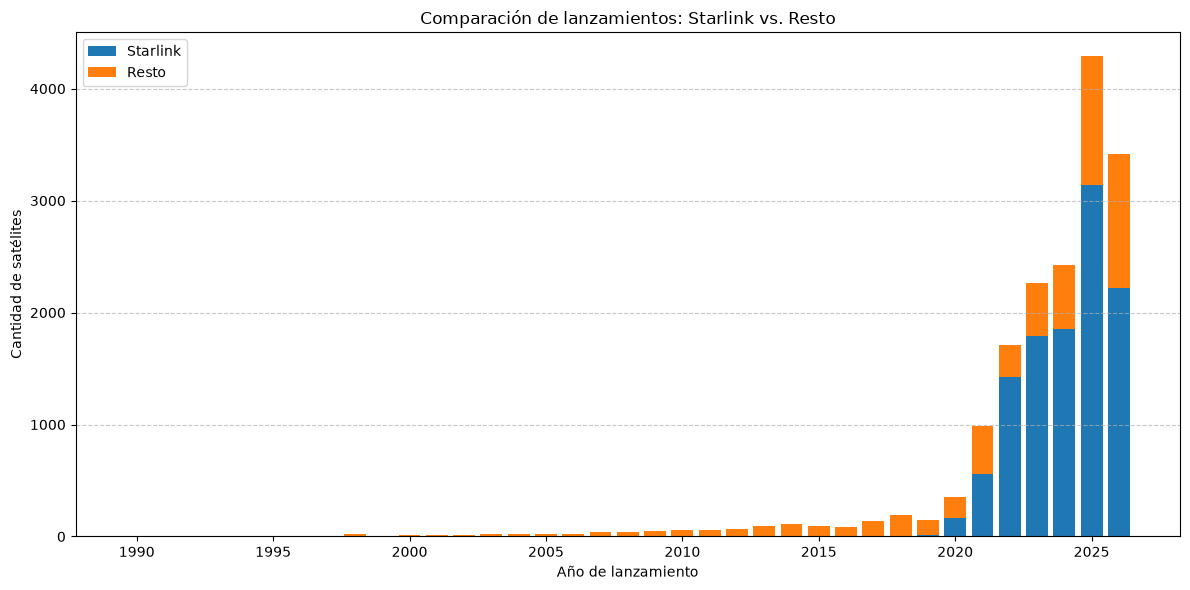

In [2]:
registros_starlink = [r for r in registros if grupo(r["OBJECT_NAME"]) == "Starlink"]
registros_resto = [r for r in registros if grupo(r["OBJECT_NAME"]) != "Starlink"]

starlink_90_26 = {a: c for a, c in lanzamientos_por_anio(registros_starlink).items() if 1990 <= a <= 2026}
resto_90_26 = {a: c for a, c in lanzamientos_por_anio(registros_resto).items() if 1990 <= a <= 2026}

graficar_lanzamientos_apilados(starlink_90_26, resto_90_26, guardar=False)

## 2. La carrera de las megaconstelaciones (2015–2026)
* **Constelaciones tradicionales (GPS, Iridium):** despliegues acotados, planificados para reemplazo puntual de flota.
* **Primeras constelaciones comerciales LEO (Planet, OneWeb):** marcan el inicio de los lotes de decenas o cientos de satélites entre 2017 y 2022.
* **Despliegue masivo (Starlink):** rompe la escala histórica a partir de 2020 con lanzamientos recurrentes de miles de unidades por año.

## importamos las siguientes funciones desde "catálogo.py":

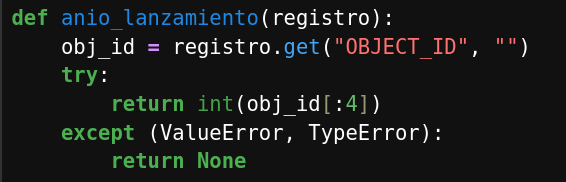

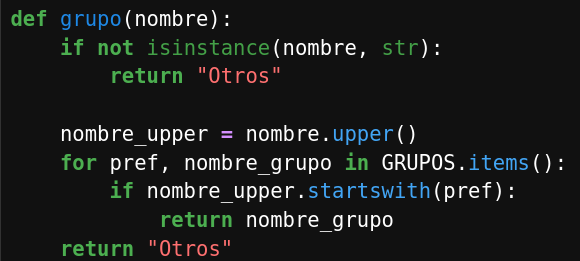

In [4]:
'''creamos una función para mostrar las evoluciones de los lanzamientos desde 2015 hasta 2026'''

from catalogo import anio_lanzamiento, grupo
import matplotlib.pyplot as plt 

def graficar_evolucion_constelaciones_15_26(registros, grupos_intereses, anio_inicio, anio_fin, guardar):
    if grupos_intereses is None:
        grupos_intereses = ["STARLINK", "ONEWEB", "KUIPER", "QUINFAN", "IRIDIUM","GLOBALSTAR", "NAVSTAR", "BEIDOU"]

    anios = list(range(anio_inicio, anio_fin + 1))
    conteos = {g: {a : 0 for a in anios} for g in grupos_intereses}

    for reg in registros:
        g = grupo(reg["OBJECT_NAME"])
        if g in conteos:
            a = anio_lanzamiento(reg)
            if anio_inicio <= a <= anio_fin:
                conteos[g][a] += 1

    plt.figure(figsize=(12,6))
    for g in grupos_intereses:
        valores = [conteos[g][a] for a in anios]
        plt.plot(anios, valores, marker="o", linewidth=2, label=g)

    plt.title(f"Evolución de lanzamientos por constelación ({anio_inicio}–{anio_fin})")
    plt.xlabel("Año de lanzamiento")
    plt.ylabel("Cantidad de satélites lanzados")
    plt.xticks(anios)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()

    if guardar:
        plt.savefig("salidas/evolucion_constelaciones_15_26.png", dpi=300)
    plt.show()

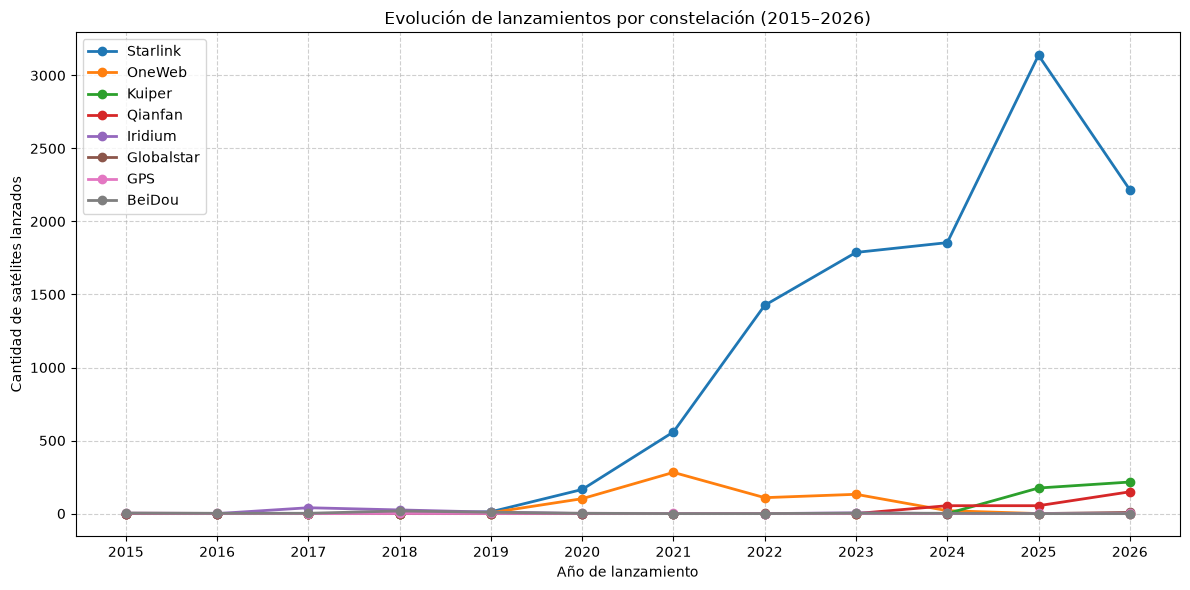

In [11]:
graficar_evolucion_constelaciones_15_26(
    registros,
    grupos_intereses = ["Starlink","OneWeb", "Kuiper", "Qianfan", "Iridium","Globalstar", "GPS", "BeiDou"],
    anio_inicio=2015,
    anio_fin=2026,
    guardar=True
)

## 3. ¿Dónde se ubican estas constelaciones? (Impacto en órbita baja)
* Las megaconstelaciones comerciales operan en **órbita terrestre baja (LEO)** para minimizar la latencia de comunicaciones y maximizar la resolución de observación.
* Esto genera una fuerte concentración en la franja de **500 a 600 km** de altitud.

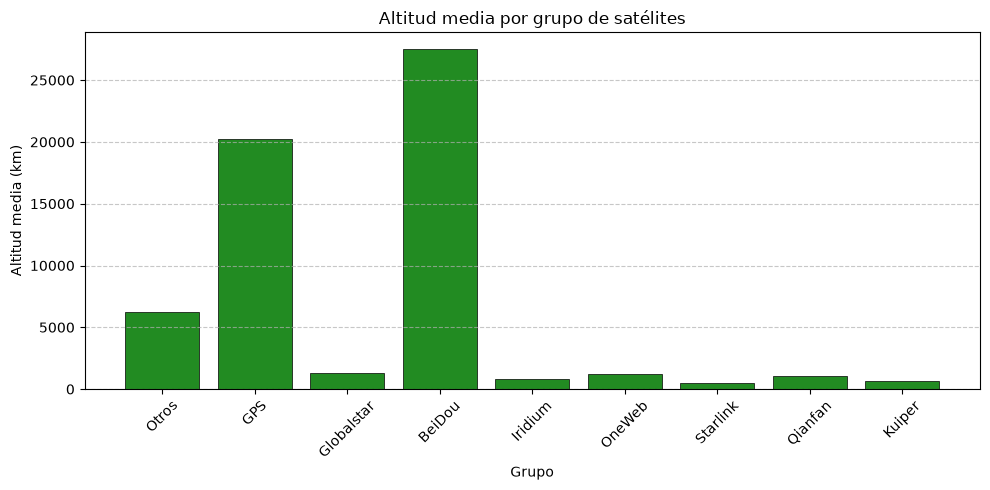

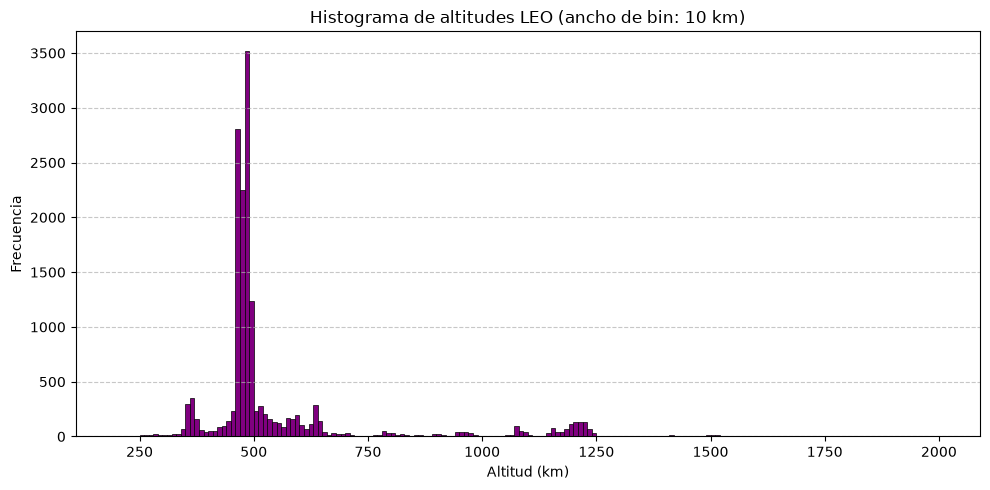

In [4]:
resumen = resumen_por_grupo(satelites)
graficar_altitud_media(resumen, guardar=False)
graficar_altitudes_leo(satelites, ancho_bin=10, guardar=False)

## 4. Conclusiones
1. **Cambio de paradigma**

Pasamos de constelaciones gubernamentales o de nicho (decenas de satélites) a infraestructuras comerciales globales de miles de satélites

2. **Dominio de LEO**

La reducción de costos de lanzamiento permitió poblar la órbita baja entre 500 y 1.200 km, concentrando allí más de dos tercios de los satélites activos actuales

3. **Desafío futuro**

La alta densidad en franjas específicas de LEO exige mayor coordinación internacional para evitar colisiones y gestionar la basura espacial